In [2]:
# resolvendo imports ...

from selecao_e_preparacao import buildDataset, filterDataset
import matplotlib.pyplot as plt
import numpy as np

# EXPERIMENTO 1: DRONE SAUDÁVEL
Para este experimento, vamos utilizar um drone saudável. Ou seja, iremos usar a categoria f0.
Segue abaixo a tabela com todas as especificações que utilizaremos para este experimento:

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F0_SV0_SP1_C1_R1.mat` | Saudável | 0 | 1 | 1 | 1 | 600.000 | 10.000 Hz | 60 s | Mesmas condições experimentais |

In [3]:
dataset = buildDataset()    # carrega todo o dataset

In [4]:
dataset_f0 = filterDataset( # filtra com base nos parâmetros definidos.
    dataset=dataset,
    condition=0,
    severity=0,
    speed=1,
    channel=1,
    recording=1,
)

In [ ]:
#nesse bloco vamos criar uma função que automaticamente plota o dataset filtrado quando chamada.
# ela obviamente vai ser reutilizada a posteriori.


def plotDataset(filtered_dataset):

    figure, axis = plt.subplots(figsize=(12, 4))

    for record in filtered_dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        condition, severity, speed, channel, recording = record[3:8]
        label = (
            f"F{condition} SV{severity} SP{speed} "
            f"C{channel} R{recording}"
        )
        axis.plot(timestamp, acceleration, label=label)

    axis.set_title("Sinal de aceleração no domínio do tempo")
    axis.set_xlabel("Tempo (s)")
    axis.set_ylabel("Aceleração")

    axis.legend()

    axis.grid(True)
    figure.tight_layout()
    plt.show()

    return figure, axis



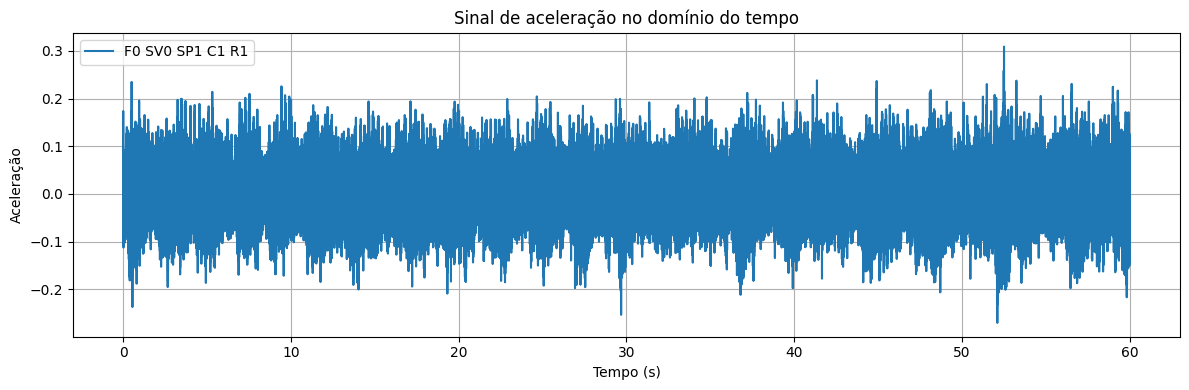

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [7]:
# agora vamos plotar o nosso sinal cujos parâmetros foram definidos na tabela:

plotDataset(dataset_f0)

In [ ]:
# LKKKKKKKKKK ok talvez deveríamos usar uma escala de tempo menor para visualizar ...

def filterDatasetByTimeInterval(dataset, start_time, end_time):
    filtrado = []

    for record in dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        intervalo = (timestamp >= start_time) & (timestamp <= end_time)
        if not np.any(intervalo):
            continue

        samples = np.flatnonzero(intervalo)
        sample_1 = samples[0]
        sample_f = samples[-1] + 1

        filtrado_r = list(record)
        filtrado_r[0] = acceleration[sample_1:sample_f]
        filtrado_r[2] = timestamp[sample_1:sample_f]

        filtrado.append(filtrado_r)

    return filtrado

In [23]:
dataset_f0_small = filterDatasetByTimeInterval(dataset=dataset_f0,
                                               start_time=dataset_f0[0][2].min(),
                                               end_time=dataset_f0[0][2].min()+0.2)

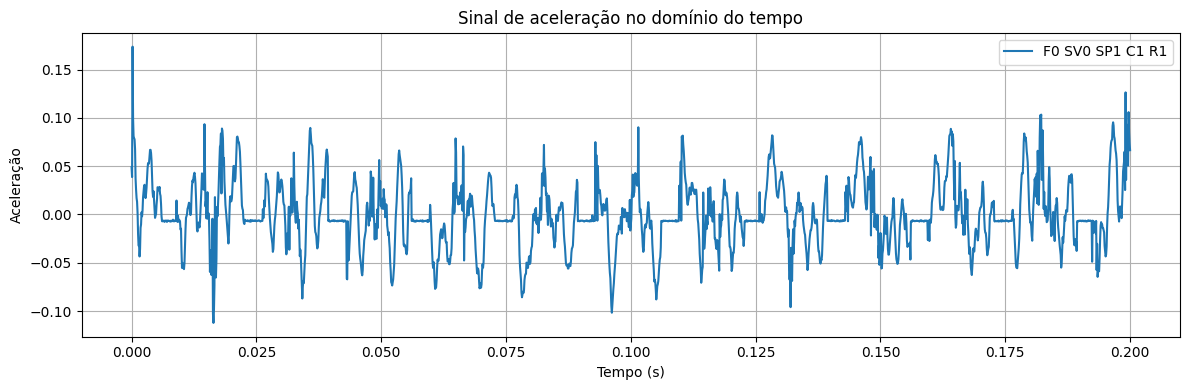

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [24]:
plotDataset(dataset_f0_small)

Observamos acima o padrão típico das oscilações para hélices saudáveis.

# EXPERIMENTO 2: CONDIÇÕES DE FALHA

Aqui, iremos experimentar com a condição de falha f1, com severidade máxima.

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F1_SV1_SP1_C1.mat` | Não-saudável | 3 | 1 | 1 | 1* | 600.000 | 10.000 Hz | 60 s | Mesma velocidade, canal, frequência e duração da referência saudável |

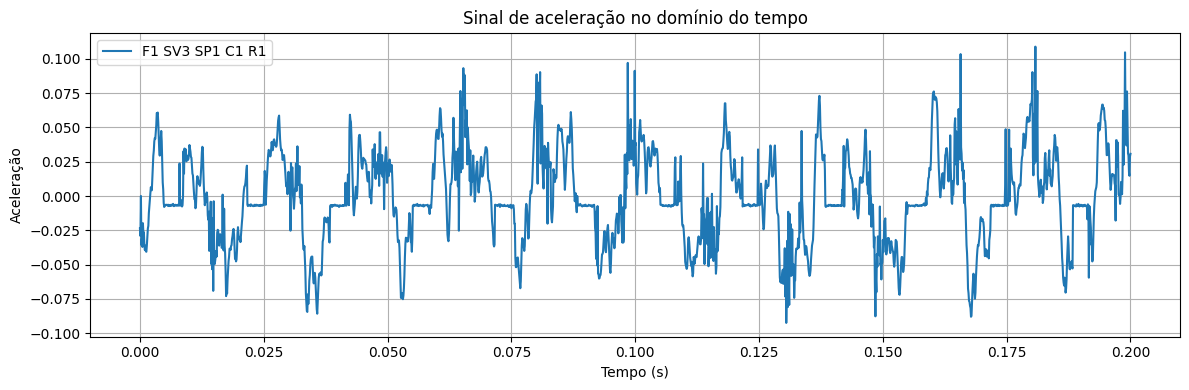

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [31]:
dataset_f1 = filterDataset(
    dataset=dataset,
    condition=1,
    severity=3,
    speed=1,
    channel=1,
    recording=1,
)

dataset_f1_small = filterDatasetByTimeInterval(dataset=dataset_f1,
                                               start_time=dataset_f1[0][2].min(),
                                               end_time=dataset_f1[0][2].min()+0.2)

plotDataset(dataset_f1_small)

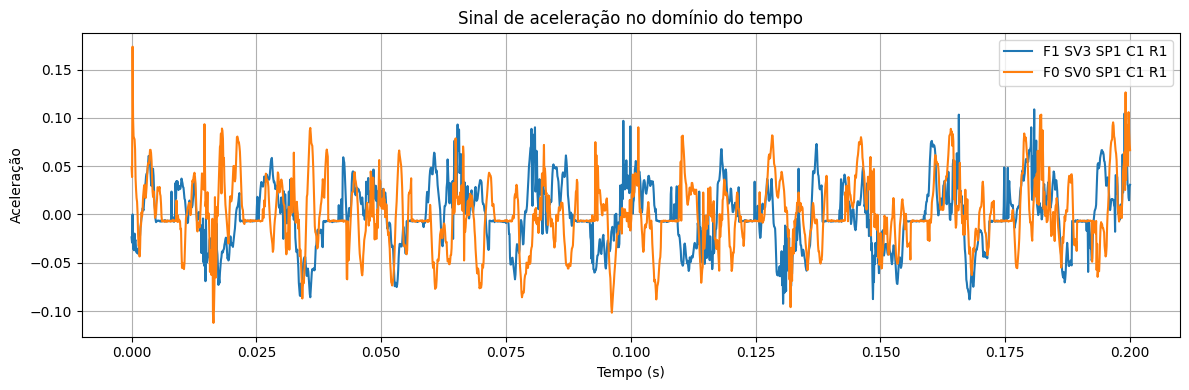

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [33]:
# show di bolations. Funcionou, agora queremos plotar os dois lado a lado. Para fazer isso, basta combinar os dois:

combined_ds = [dataset_f1_small[0], dataset_f0_small[0]]
plotDataset(combined_ds)

Sinceramente, no olho não consigo notar muito a diferença entre os dois ... até sendo o f1 portador de um grau de severidade bastante alto ... 